In [1]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt
import numpy as np
import random

In [7]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)
# Setosa와 Versicolor만 선택
df = df[df["species"].isin(["setosa", "versicolor"])].copy()
df["class"] = df["species"].map({"setosa": 0, "versicolor": 1})
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species  class
0           5.1          3.5           1.4          0.2  setosa      0
1           4.9          3.0           1.4          0.2  setosa      0
2           4.7          3.2           1.3          0.2  setosa      0
3           4.6          3.1           1.5          0.2  setosa      0
4           5.0          3.6           1.4          0.2  setosa      0


In [9]:
x = torch.tensor(
    df[
        ["sepal_length", "sepal_width", "petal_length", "petal_width"]
    ].values,
    dtype=torch.float32,
)
y = torch.tensor(df["class"].values, dtype=torch.float32).reshape(-1, 1)
torch.manual_seed(42)
tr = []
te = []
for i in [0, 1]:
    ci = torch.where(y.squeeze() == i)[0]
    ci = ci[torch.randperm(len(ci))]
    s = int(len(ci) * 0.8)
    tr.extend(ci[:s])
    te.extend(ci[s:])
tr = torch.tensor(tr)[torch.randperm(len(tr))]
te = torch.tensor(te)[torch.randperm(len(te))]
xtr = x[tr]
xte = x[te]
ytr = y[tr]
yte = y[te]
mean = xtr.mean(dim=0)
std = xtr.std(dim=0).clamp(min=1e-8)
xtr = (xtr - mean) / std
xte = (xte - mean) / std
print(xtr.shape, xte.shape)
print(ytr.shape, yte.shape)

torch.Size([80, 4]) torch.Size([20, 4])
torch.Size([80, 1]) torch.Size([20, 1])


In [ ]:
trds = TensorDataset(xtr, ytr)
teds = TensorDataset(xte, yte)
trdl = DataLoader(trds, shuffle=True)
tedl = DataLoader(teds, shuffle=False)
n = len(trdl.dataset)
print(n)

80


In [12]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(4, 100), nn.Sigmoid(), nn.Linear(100, 1), nn.Sigmoid()
        )

    def forward(self, x):
        x = self.linear(x)
        return x


m = MLP()

In [13]:
LR = 1e-1
EPOCH = 100
op = optim.SGD(m.parameters(), lr=LR)
cri = nn.BCELoss()
lh = []
m.train()
for ep in range(EPOCH):
    rloos = 0
    for xb, yb in trdl:
        yh = m(xb)
        loss = cri(yh, yb)
        op.zero_grad()
        loss.backward()
        op.step()
        loss += loss.item() * xb.shape[0]
    eloss = loss / n
    lh.append(eloss.item())
    print(f"EPOCH: {ep+1}, train loss: {eloss:.4f}")

EPOCH: 1, train loss: 0.1337
EPOCH: 2, train loss: 0.1350
EPOCH: 3, train loss: 0.1086
EPOCH: 4, train loss: 0.0914
EPOCH: 5, train loss: 0.0812
EPOCH: 6, train loss: 0.0795
EPOCH: 7, train loss: 0.0615
EPOCH: 8, train loss: 0.0679
EPOCH: 9, train loss: 0.0553
EPOCH: 10, train loss: 0.0569
EPOCH: 11, train loss: 0.0405
EPOCH: 12, train loss: 0.0452
EPOCH: 13, train loss: 0.0427
EPOCH: 14, train loss: 0.0426
EPOCH: 15, train loss: 0.0336
EPOCH: 16, train loss: 0.0326
EPOCH: 17, train loss: 0.0335
EPOCH: 18, train loss: 0.0287
EPOCH: 19, train loss: 0.0326
EPOCH: 20, train loss: 0.0334
EPOCH: 21, train loss: 0.0258
EPOCH: 22, train loss: 0.0259
EPOCH: 23, train loss: 0.0189
EPOCH: 24, train loss: 0.0252
EPOCH: 25, train loss: 0.0196
EPOCH: 26, train loss: 0.0230
EPOCH: 27, train loss: 0.0172
EPOCH: 28, train loss: 0.0179
EPOCH: 29, train loss: 0.0168
EPOCH: 30, train loss: 0.0170
EPOCH: 31, train loss: 0.0183
EPOCH: 32, train loss: 0.0189
EPOCH: 33, train loss: 0.0158
EPOCH: 34, train lo

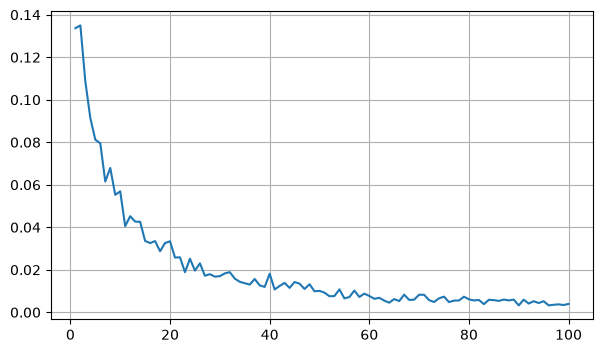

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCH + 1), lh)
plt.grid()

In [15]:
m.eval()
correct = 0
total = 0
with torch.no_grad():
    for xb, yb in tedl:
        yh = m(xb)
        pr = (yh >= 0.5).float()
        correct += (pr == yb).sum().item()
        total += yb.numel()
accuracy = correct / total * 100
print(f"Test accuracy: {correct}/{total}({accuracy:.1f}%)")

Test accuracy: 20/20(100.0%)


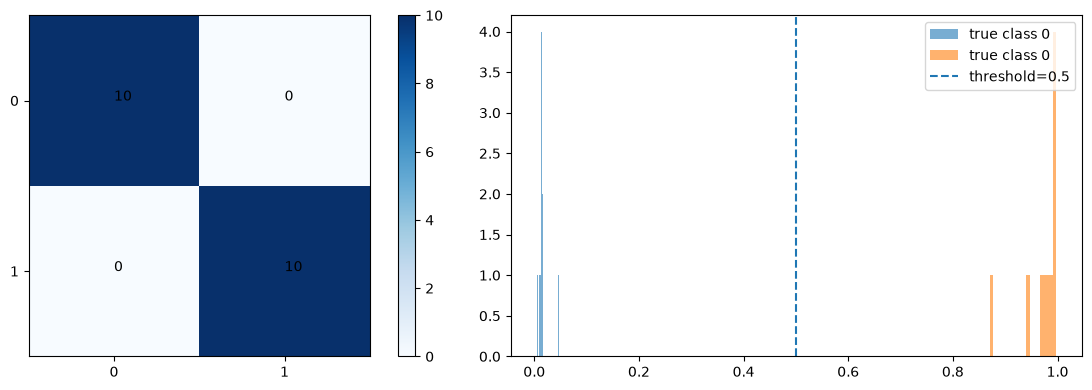

In [17]:
m.eval()
yta = []
ypa = []
with torch.no_grad():
    for xb, yb in tedl:
        yh = m(xb)
        yta.append(yb.numpy().reshape(-1))
        ypa.append(yh.numpy().reshape(-1))
yt = np.concatenate(yta).astype(int)
yp = np.concatenate(ypa)
ypr = (yp >= 0.5).astype(int)
cm = np.zeros((2, 2), dtype=int)
for t, p in zip(yt, ypr):
    cm[t, p] += 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks([0, 1], labels=["0", "1"])
axes[0].set_yticks([0, 1], labels=["0", "1"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j])
fig.colorbar(im, ax=axes[0])
axes[1].hist(yp[yt == 0], bins=20, alpha=0.6, label="true class 0")
axes[1].hist(yp[yt == 1], bins=20, alpha=0.6, label="true class 0")
axes[1].axvline(0.5, linestyle="--", label="threshold=0.5")
axes[1].legend()
plt.tight_layout()
plt.show()